# 05 · Why does a model work here and not there?

We relate each model's per-series accuracy (CV folds) to the series characteristics computed on pre-holdout data (`reports/series_characteristics.csv`). Every statement below cites a number produced in this notebook.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
def show(fig): display(Image(filename=f"reports/figures/{fig}"))
def J(path): return json.load(open(path))

In [2]:
import contextlib, io
from src.analysis import why
with contextlib.redirect_stdout(io.StringIO()):
    why.main()
W = J("reports/why_summary.json")
print("regenerated")

regenerated


## 1. Where SARIMA wins and loses

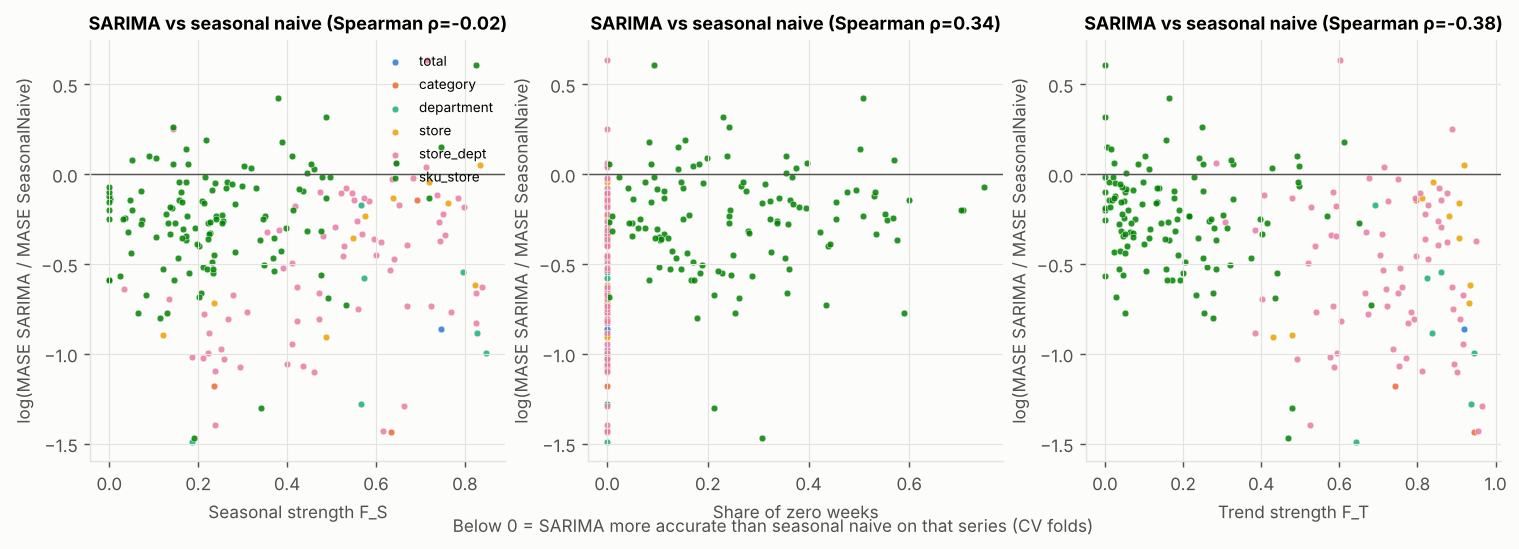

,feature,bin,n,sarima_beats_snaive,sarima_beats_lgbm,sarima_beats_ets,median_mase_SARIMA,median_mase_LightGBM,median_mase_ETS,median_mase_SeasonalNaive
0,seasonal_strength,"(-0.01, 0.2]",60,0.867,0.383,0.500,0.634,0.575,0.614,0.889
1,seasonal_strength,"(0.2, 0.4]",64,0.922,0.438,0.484,0.614,0.571,0.617,0.903
2,seasonal_strength,"(0.4, 0.6]",46,0.891,0.457,0.674,0.653,0.624,0.645,0.920
3,seasonal_strength,"(0.6, 1.0]",41,0.829,0.659,0.854,0.702,0.814,0.909,1.042
4,share_zeros,"(-0.01, 0.0001]",91,0.945,0.593,0.714,0.527,0.560,0.603,0.976
5,share_zeros,"(0.0001, 0.2]",54,0.815,0.315,0.593,0.691,0.651,0.663,0.879
6,share_zeros,"(0.2, 0.4]",42,0.833,0.476,0.524,0.658,0.636,0.710,0.891
7,share_zeros,"(0.4, 1.0]",24,0.875,0.333,0.333,0.784,0.734,0.784,1.098
8,trend_strength,"(-0.01, 0.3]",98,0.847,0.378,0.561,0.731,0.715,0.750,0.920
9,trend_strength,"(0.3, 0.6]",42,0.881,0.476,0.452,0.613,0.609,0.625,0.903


In [3]:
show("11_sarima_relative_error_vs_characteristics.png")
b = pd.read_csv("reports/tables/why_binned_win_rates.csv")
display(b[["feature", "bin", "n", "sarima_beats_snaive", "sarima_beats_lgbm", "sarima_beats_ets", "median_mase_SARIMA", "median_mase_LightGBM", "median_mase_ETS", "median_mase_SeasonalNaive"]].round(3))

**Evidence**
- **Seasonal strength:** SARIMA's win rate vs LightGBM rises from **38%** (F_S ≤ 0.2) to 44%, 46% and **66%** (F_S > 0.6); vs ETS from 50% to **85%**. With strong seasonality SARIMA's median MASE is 0.70 vs LightGBM 0.81 and ETS 0.91.
- **Zeros:** on zero-free series SARIMA beats LightGBM on **59%**; on series with zeros only **32-48%**.
- **Trend strength > 0.8:** SARIMA beats LightGBM 59% and ETS 82%.
- **Versus seasonal naive** SARIMA wins 79-95% of series in *every* bin: the lag-52 model plus differencing captures growth that a pure seasonal copy cannot.

**So SARIMA works where** the series is an aggregate (no zeros), has strong trend and seasonality, and has a long, mostly stable history: department and category-type series, where it has the best mean MASE (department 0.519).
**It loses where** demand is SKU-level, zero-inflated and weakly seasonal (median F_S of SKUs about 0.2). ARIMA assumes continuous, roughly Gaussian errors, and with 24-37% zero weeks there is little linear autocorrelation structure to exploit. AutoARIMA itself recognises this: it selects seasonal differencing (D = 1) on only **1.7%** of SKU fits vs 37% of aggregate fits.

In [4]:
display(pd.read_csv("reports/tables/why_by_class.csv").round(3))
print(json.dumps(W["sarima_orders"], indent=1))

,cls,n,sarima_beats_snaive,sarima_beats_lgbm,sarima_beats_ets,sarima_best_or_within5pct,seasonal_strength,share_zeros,trend_strength
0,SKU-erratic,30,0.733,0.333,0.600,0.200,0.190,0.146,0.155
1,SKU-intermittent,30,0.900,0.533,0.467,0.233,0.205,0.374,0.115
2,SKU-lumpy,30,0.833,0.267,0.400,0.167,0.168,0.361,0.052
3,SKU-smooth,30,0.867,0.367,0.600,0.333,0.239,0.094,0.244
4,category,3,1.000,0.667,0.667,0.333,0.634,0.000,0.796
5,department,7,1.000,0.857,1.000,0.714,0.573,0.000,0.838
6,store,10,0.900,0.600,0.800,0.200,0.607,0.000,0.893
7,store_dept,70,0.943,0.557,0.671,0.371,0.531,0.000,0.744
8,total,1,1.000,1.000,1.000,1.000,0.746,0.000,0.919


{
 "share_with_D1": {
  "Aggregate": 0.374,
  "SKU": 0.017
 },
 "share_with_any_seasonal_term": {
  "Aggregate": 0.943,
  "SKU": 0.725
 },
 "share_d1": {
  "Aggregate": 0.974,
  "SKU": 0.693
 },
 "most_common_holdout": {
  "ARIMA(0,1,1)(1,0,0)[52]": 10,
  "ARIMA(0,1,1)": 10,
  "ARIMA(0,1,1)(0,0,1)[52]": 9,
  "ARIMA(1,1,2)(1,0,0)[52]": 7,
  "ARIMA(1,1,1)(0,0,1)[52]": 6,
  "ARIMA(1,0,1)(1,0,0)[52] with non-zero mean": 6,
  "ARIMA(0,1,2)(1,0,1)[52]": 5,
  "ARIMA(0,1,2)(0,0,1)[52]": 5
 }
}


## 2. SARIMA vs LightGBM head to head

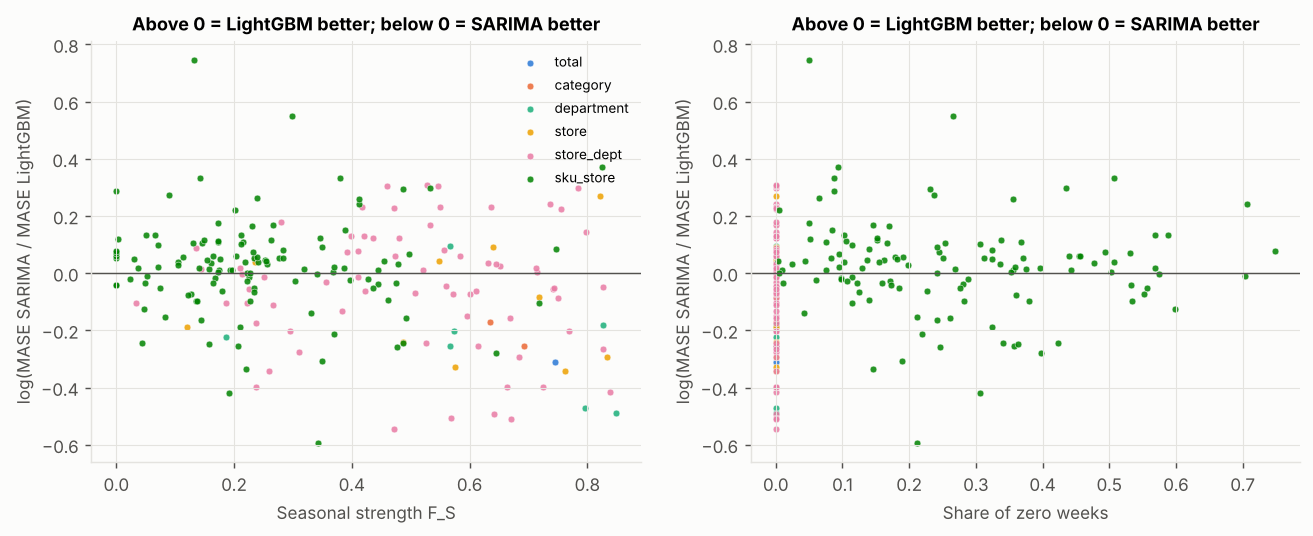

,feature,group,spearman_rho,p,n
0,seasonal_strength,all,-0.178,0.010,211
3,trend_strength,all,-0.167,0.015,211
6,share_zeros,all,0.160,0.020,211
9,cv,all,0.184,0.007,211
12,adi,all,0.160,0.020,211
15,cv2,all,0.211,0.002,211
18,log_mean,all,-0.174,0.011,211
19,log_mean,Aggregate,-0.179,0.090,91
20,log_mean,SKU,0.217,0.017,120


In [5]:
show("12_sarima_vs_lightgbm.png")
h = pd.read_csv("reports/tables/why_sarima_vs_lgbm_spearman.csv")
display(h[h.p < 0.1].round(3))

**LightGBM wins** on SKUs (bootstrap ΔMASE +0.018 in its favour). Its advantages there: it **pools information across 211 series** (a single SKU has too little signal, but similar SKUs share patterns), uses **exogenous drivers** (SNAP schedule, events, price), and handles nonlinear effects and zero-inflation without distributional assumptions.
**LightGBM loses** on aggregates with strong trend (bootstrap ΔMASE −0.050 in SARIMA's favour, significant): a tree cannot extrapolate a level beyond its training range, so it relies on the recent-scale normalisation, and it has only 91 smooth aggregate series to learn their specific dynamics from, while SARIMA models each one's own autocorrelation.

## 3. ETS, Prophet, DHR and baselines

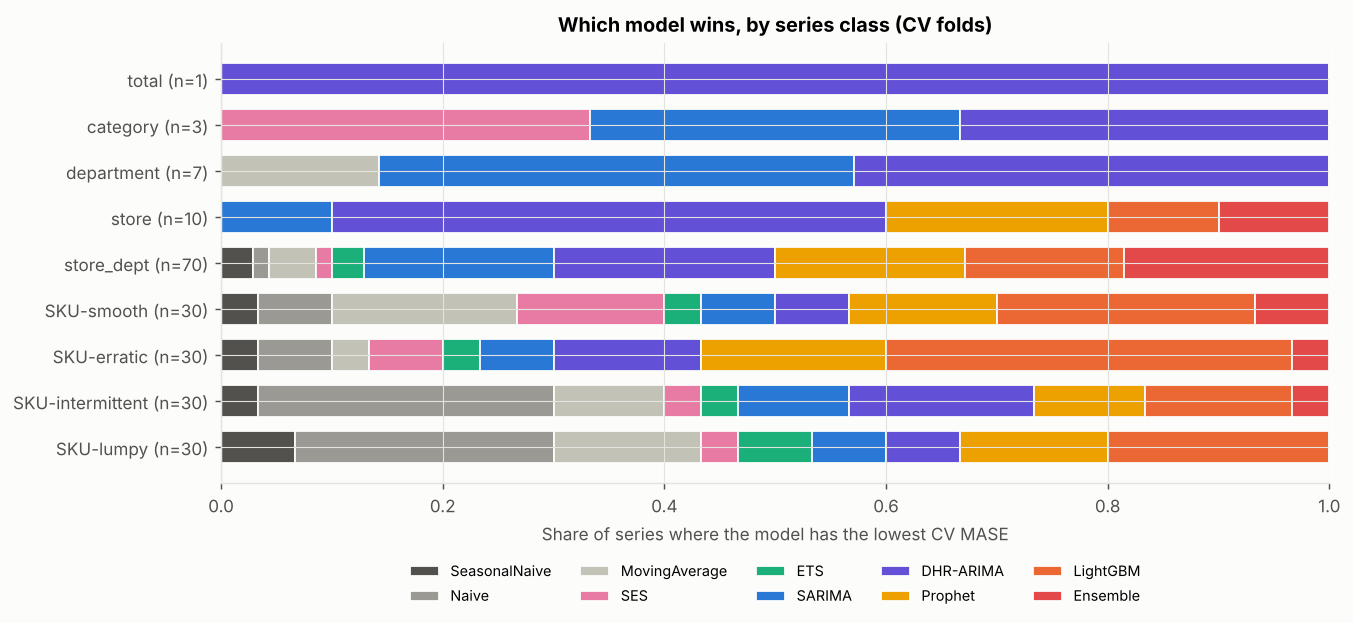

,DHR-ARIMA,ETS,Ensemble,LightGBM,MovingAverage,Naive,Prophet,SARIMA,SES,SeasonalNaive
row_0,,,,,,,,,,
SKU-erratic,4,1,1,11,1,2,5,2,2,1
SKU-intermittent,5,1,1,4,3,8,3,3,1,1
SKU-lumpy,2,2,0,6,4,7,4,2,1,2
SKU-smooth,2,1,2,7,5,2,4,2,4,1
category,1,0,0,0,0,0,0,1,1,0
department,3,0,0,0,1,0,0,3,0,0
store,5,0,1,1,0,0,2,1,0,0
store_dept,14,2,13,10,3,1,12,12,1,2
total,1,0,0,0,0,0,0,0,0,0


In [6]:
show("13_winner_share_by_class.png")
display(pd.read_csv("reports/tables/why_winner_counts_cv.csv").set_index(pd.read_csv("reports/tables/why_winner_counts_cv.csv").columns[0]))

- **DHR-ARIMA** (Fourier + holidays + SNAP) ties SARIMA overall (bootstrap CI includes 0) and wins most total/store series (total 0.326 vs SARIMA 0.331; store 0.431 vs 0.466). Explicit, known drivers help where the monthly SNAP cycle and moving holidays matter most: large, FOODS-heavy aggregates.
- **ETS** is clearly worse than SARIMA on aggregates (ΔMASE −0.089 in SARIMA's favour), and its intervals are badly under-covered there. With s = 52 it must carry 52 seasonal states initialised heuristically. It does best on **lumpy SKUs** (0.739, best of all), where heavy smoothing of a noisy level is what matters.
- **Prophet** is mid-table (0.774) and has the most negative SKU bias (-12.9% median). Its smooth trend + Fourier structure ignores short-term autocorrelation, which matters at weekly grain.
- **Naive / moving average** win a handful of intermittent and lumpy SKUs (Naive wins 8 of 30 intermittent): when demand is mostly noise, the simplest level estimate is hard to beat.
- **Seasonal naive** wins almost nowhere because growth dominates (median aggregate bias −11.6%).

## 4. Where the model choice does not matter

In [7]:
print("CV->holdout winner agreement per series:", round(W["winner_stability_cv_to_holdout"], 3))
print("decision tree accuracy predicting the per-series winner:", round(W["decision_tree_cv_accuracy"], 3), "vs majority baseline", round(W["decision_tree_majority_baseline"], 3))
print(open("reports/tables/why_decision_tree.txt").read()[:1500])

CV->holdout winner agreement per series: 0.128
decision tree accuracy predicting the per-series winner: 0.204 vs majority baseline 0.185
5-fold CV accuracy predicting the CV-winning model: 0.204 (+/- 0.054); majority-class baseline: 0.185

|--- log_mean <= 4.05
|   |--- seasonal_strength <= 0.55
|   |   |--- log_mean <= 0.57
|   |   |   |--- weights: [6.00, 3.00, 3.00, 3.00, 8.00, 12.00, 8.00, 4.00, 2.00, 1.00] class: Naive
|   |   |--- log_mean >  0.57
|   |   |   |--- weights: [10.00, 2.00, 10.00, 33.00, 8.00, 7.00, 8.00, 10.00, 7.00, 5.00] class: LightGBM
|   |--- seasonal_strength >  0.55
|   |   |--- trend_strength <= 0.76
|   |   |   |--- weights: [5.00, 2.00, 1.00, 1.00, 0.00, 0.00, 9.00, 1.00, 0.00, 1.00] class: Prophet
|   |   |--- trend_strength >  0.76
|   |   |   |--- weights: [2.00, 0.00, 3.00, 1.00, 0.00, 1.00, 3.00, 7.00, 0.00, 0.00] class: SARIMA
|--- log_mean >  4.05
|   |--- trend_strength <= 0.83
|   |   |--- weights: [9.00, 0.00, 0.00, 0.00, 1.00, 0.00, 0.00, 1.00, 

**This is the most important honest finding:** the model with the best CV score on a series is also best on the holdout for only **12.8%** of series, and a decision tree on the characteristics predicts the per-series winner with 20.4% accuracy vs 18.5% for always guessing the most common winner. Per-series DM tests find no significant difference for most series (notebook 04).
So **per-series model selection is mostly chasing noise**. The robust, reproducible differences are at the **group level** (aggregates vs SKUs, strong vs weak seasonality), and that is how the decision guide below is written.

## 5. Decision guide (from this study's evidence)
| Series characteristics | Prefer | Why (evidence) |
|---|---|---|
| Aggregate (store/department/category), no zeros, F_T > 0.6, F_S > 0.5 | **SARIMA** (or DHR-ARIMA) | best single model on aggregates (MASE 0.636); beats LightGBM 59-66% in these bins; calibrated intervals |
| Large aggregate with known calendar drivers (SNAP, moving holidays) | **DHR-ARIMA** | best on total/category/store; handles the 52.18-week year and the monthly cycle |
| Many related SKU series, zeros 5-40%, weak seasonality | **global LightGBM** | best single model on SKUs (0.733); pools across series; still best without the price assumption (0.741) |
| Lumpy SKU (ADI ≥ 1.32, CV² ≥ 0.49) | **ETS / SES** or the ensemble | ETS best on lumpy (0.739); smoothing beats structure |
| Any level, if you can only deploy one thing | **Ensemble (SARIMA + LightGBM)** | best overall CV (0.681) and holdout (0.668); better than SARIMA on 68% of series |
| Strong growth / trend | never seasonal naive alone | MASE 1.11 on aggregates; −11.6% bias |